# 1. Konfiguracja środowiska i urządzeń

In [28]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | urządzenie: cuda


# 2. Przygotowanie danych (FashionMNIST)

Klasy: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Trening: 60000 | Test: 10000
Kształt tensora obrazu: (1, 28, 28)
min/max wartości: -0.81 2.023
Etykieta: 9 -> Ankle boot


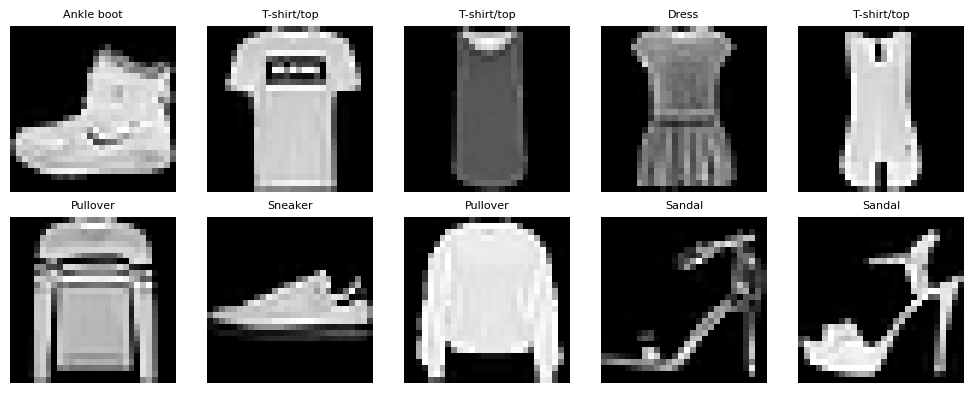

In [29]:
mean, std = 0.2860, 0.3530

tf = transforms.Compose([
    transforms.ToTensor(), # Konwersja do tensora [1, 28, 28] i skalowanie do [0, 1]
    transforms.Normalize((mean,), (std,)) # Standaryzacja: (x - mean) / std
])

train_ds = torchvision.datasets.FashionMNIST("./data", train=True, download=True, transform=tf)
test_ds  = torchvision.datasets.FashionMNIST("./data", train=False, download=True, transform=tf)
classes = train_ds.classes
print("Klasy:", classes)
print("Trening:", len(train_ds), "| Test:", len(test_ds))

# Paczki (batch) - karta graficzna przetwarza wiele obrazów równolegle
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl  = DataLoader(test_ds, batch_size=256, shuffle=False)

img_t, label = train_ds[0]
print("Kształt tensora obrazu:", tuple(img_t.shape)) # [1, 28, 28]
print("min/max wartości:", round(img_t.min().item(), 3), round(img_t.max().item(), 3))
print("Etykieta:", label, "->", classes[label])

# Przykładowe obrazy z każdej klasy
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, idx in zip(axes.flat, range(10)):
    im, lb = train_ds[idx]
    ax.imshow(im.squeeze()*std + mean, cmap="gray")
    ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

# 3. Definicja modelu MLP

In [30]:
class MLP(nn.Module):
    def __init__(self, in_dim=28*28, hidden=(256, 128), n_classes=10):
        super().__init__()
        layers = [nn.Flatten()] # Spłaszczenie obrazu [N, 1, 28, 28] -> [N, 784]
        prev_dim = in_dim
        for h in hidden:
            layers.append(nn.Linear(prev_dim, h)) # Warstwa gęsta
            layers.append(nn.ReLU()) # Nieliniowość ReLU
            prev_dim = h
        layers.append(nn.Linear(prev_dim, n_classes)) # Wyjście: 10 logitów
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Model bazowy
model_bazowy = MLP()
n_params = sum(p.numel() for p in model_bazowy.parameters())
print(model_bazowy)
print("Liczba parametrów modelu bazowego:", n_params)

# Test forward na jednej paczce
xb, yb = next(iter(train_dl))
print("Wejście:", tuple(xb.shape), "-> wyjście:", tuple(model_bazowy(xb).shape))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Liczba parametrów modelu bazowego: 235146
Wejście: (128, 1, 28, 28) -> wyjście: (128, 10)


# 4.Funkcje pomocnicze: trening i ewaluacja

In [31]:
def evaluate(model, dl):
    model.eval()
    correct = total = 0
    loss_sum = 0.0
    crit = nn.CrossEntropyLoss(reduction="sum")
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb) # logity [N, 10]
            loss_sum += crit(out, yb).item()
            preds = out.argmax(1)
            correct += (preds == yb).sum().item()
            total += yb.numel()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(yb.cpu().numpy())
    return loss_sum/total, correct/total, np.array(all_preds), np.array(all_labels)

EPOCHS = 8

def train_model(model, epochs=EPOCHS):
    criterion = nn.CrossEntropyLoss() # Wewnątrz zawiera softmax
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}

    for epoch in range(1, epochs+1):
        model.train()
        run_loss = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad() # Wyzerowanie gradientów z poprzedniej iteracji
            loss = criterion(model(xb), yb) # forward + strata
            loss.backward() # backward: gradienty (autograd)
            optimizer.step() # Aktualizacja wag
            run_loss += loss.item()*yb.numel()

        train_loss = run_loss/len(train_ds)
        test_loss, test_acc, _, _ = evaluate(model, test_dl)
        hist["train_loss"].append(train_loss)
        hist["test_loss"].append(test_loss)
        hist["test_acc"].append(test_acc)

    # Zwracamy pełne predykcje z ostatniej epoki dla macierzy pomyłek
    _, final_acc, all_preds, all_labels = evaluate(model, test_dl)
    return hist, final_acc, all_preds, all_labels

# 5. Eksperymenty: 3 warianty architektury

In [32]:
variants = {
    "V1: (128,)": (128,),
    "V2: (256, 128)": (256, 128),
    "V3: (512, 256, 128)": (512, 256, 128)
}

results = []
best_hist, best_acc, best_preds, best_labels = None, 0.0, None, None
best_model, best_name = None, ""

print("Rozpoczynam trenowanie wariantów...")
for name, hidden in variants.items():
    model = MLP(hidden=hidden).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    hist, test_acc, preds, labels = train_model(model, epochs=8)
    results.append((name, n_params, test_acc))

    if test_acc > best_acc:
        best_acc = test_acc
        best_hist = hist
        best_preds = preds
        best_labels = labels
        best_model = model
        best_name = name

# Wyświetlenie tabeli wyników
print(f"\n{'Architektura':<25} | {'Parametry':<12} | {'Accuracy Test':<12}")
print("-" * 55)
for name, params, acc in results:
    print(f"{name:<25} | {params:<12} | {acc*100:.2f}%")
print(f"\nNajlepszy wariant: {best_name} ({best_acc*100:.2f}%)")

Rozpoczynam trenowanie wariantów...

Architektura              | Parametry    | Accuracy Test
-------------------------------------------------------
V1: (128,)                | 101770       | 88.12%
V2: (256, 128)            | 235146       | 88.29%
V3: (512, 256, 128)       | 567434       | 89.30%

Najlepszy wariant: V3: (512, 256, 128) (89.30%)


# 6. Wizualizacja wyników dla najlepszego wariantu

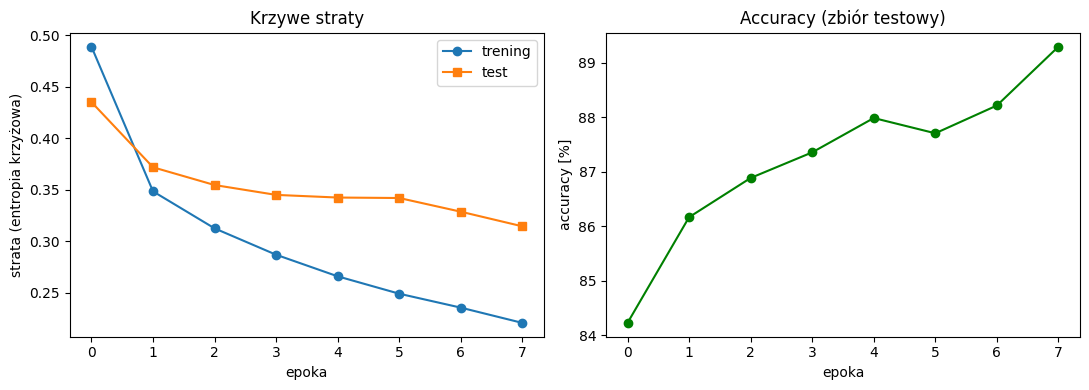

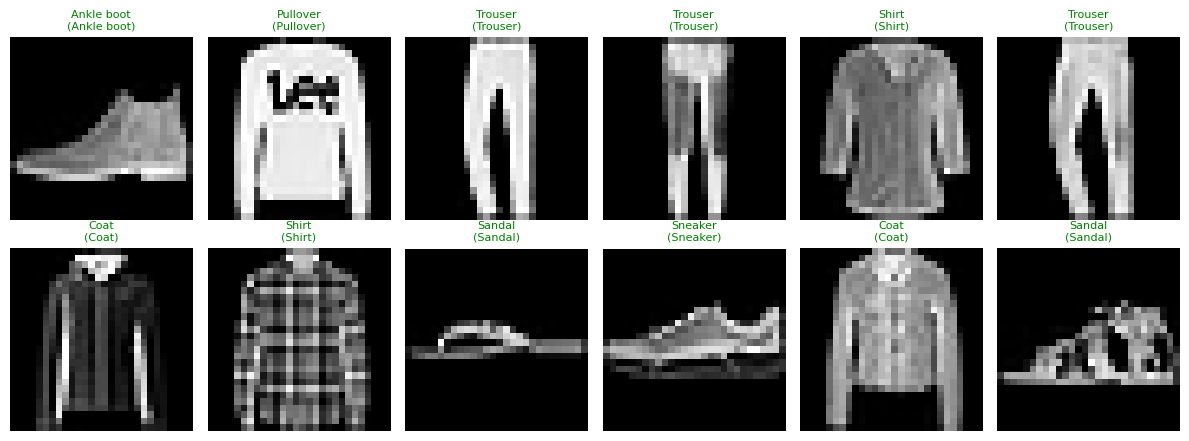

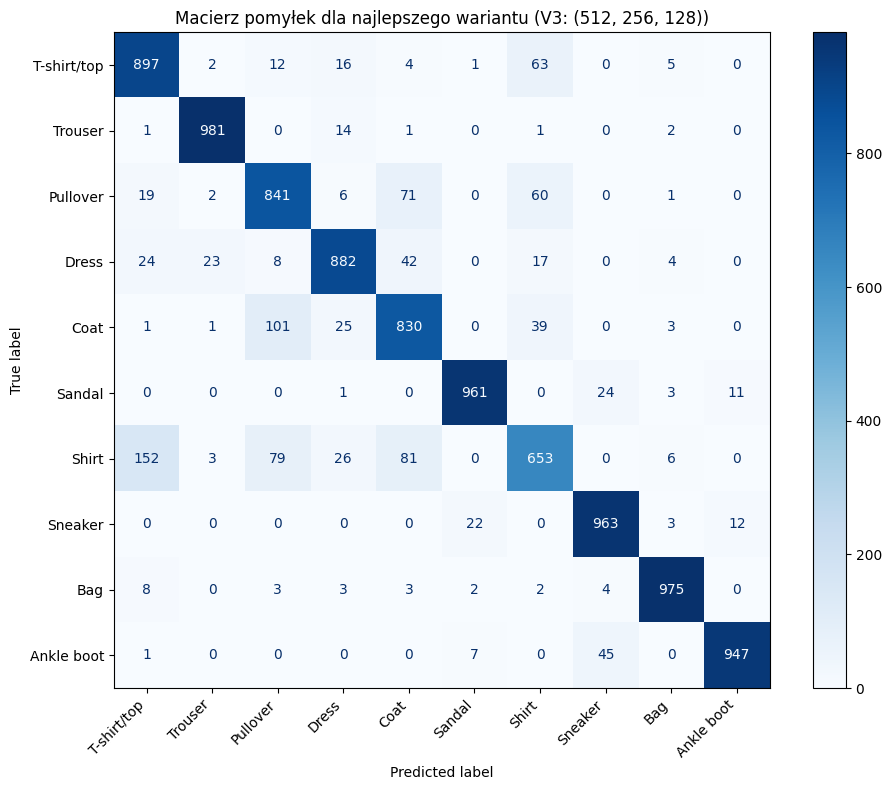

In [33]:
# 6a. Krzywe uczenia (strata trening vs test)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(best_hist["train_loss"], label="trening", marker='o')
ax1.plot(best_hist["test_loss"], label="test", marker='s')
ax1.set_xlabel("epoka"); ax1.set_ylabel("strata (entropia krzyżowa)"); ax1.legend(); ax1.set_title("Krzywe straty")
ax2.plot([a*100 for a in best_hist["test_acc"]], color="green", marker='o')
ax2.set_xlabel("epoka"); ax2.set_ylabel("accuracy [%]"); ax2.set_title("Accuracy (zbiór testowy)")
plt.tight_layout(); plt.show()

# 6b. Siatka predykcji (podgląd obrazów)
model.eval()
xb, yb = next(iter(test_dl))
with torch.no_grad():
    pred = best_model(xb.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, i in zip(axes.flat, range(12)):
    # Denormalizacja
    img = xb[i].squeeze() * std + mean
    ax.imshow(img, cmap="gray")
    ok = pred[i].item() == yb[i].item()
    ax.set_title(f"{classes[pred[i]]}\n({classes[yb[i]]})", fontsize=8, color="green" if ok else "red")
    ax.axis("off")
plt.tight_layout(); plt.show()

# 6c. Macierz pomyłek
cm = confusion_matrix(best_labels, best_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title(f"Macierz pomyłek dla najlepszego wariantu ({best_name})")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
# Wyszukanie najtrudniejszej pary klas
np.fill_diagonal(cm, 0) # Zerujemy przekątną (poprawne klasyfikacje)
max_confusion_idx = np.unravel_index(np.argmax(cm, axis=None), cm.shape)
class_1, class_2 = classes[max_confusion_idx[0]], classes[max_confusion_idx[1]]
print(f"Najtrudniejsza para klas (najwięcej pomyłek): '{class_1}' mylona z '{class_2}' (liczba błędów: {cm.max()})")

Najtrudniejsza para klas (najwięcej pomyłek): 'Shirt' mylona z 'T-shirt/top' (liczba błędów: 152)
